# Lab 6, Task 2A: Experimental 2 by 2 MIMO

Generate orthogonal sounding waveforms, collect two synchronized receiver channels, estimate the channel matrix, and compare MIMO and SISO capacity.

In [5]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Image

def find_lab_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "support" / "lab6_dsp.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the Lab 6 folder tree")

LAB_ROOT = find_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
import lab6_dsp as lab
import lab6_tools as tools
print("Lab folder:", LAB_ROOT.name)


Lab folder: Lab6


## Prepare finite dual-channel waveforms

<span style='color:#1464b4'><b>Report:</b> Record requested sample rates, carrier frequency, gain, subdevices, antenna selectors,
and file sizes.</span>

- **TX Gains:** 40, 45, 50 dB
- **RX Gain:** 60 dB
- **TX Subdevice:** A:0 A:1
- **RX Subdevice:** A:0 A:1
- **TX Antenna:** TX/RX
- **RX Antenna:** TX/RX
- **Carrier Frequency:** 2.45 GB
- **Sample Rate:** 1 MS/s
- **TX File Size:** 24,388,608 bytes
- **RX File Size:** 48,000,000 bytes

In [6]:
tx_gains_db = (40, 45, 50)
rx_gain_db = 60
tx_subdevice = "A:0 A:1"
rx_subdevice = "A:0 A:1"
tx_antenna = "TX/RX"
rx_antenna = "TX/RX"
prep_root = LAB_ROOT/'work'
prepared = tools.prepare_hardware_experiment(
    prep_root/'waveforms', prep_root/'captures', tx_gains_db, rx_gain_db,
    tx_subdevice, rx_subdevice, tx_antenna, rx_antenna
)
print('TX files:', Path(prepared['tx0_path']).name, Path(prepared['tx1_path']).name)
print('Radio configuration:', prepared['summary']['experiment'])
print('Bytes per TX file:', prepared['bytes_per_tx_file'])

TX files: lab6_tx_ch0_c64.dat lab6_tx_ch1_c64.dat
Radio configuration: {'tx_gains_db': [40, 45, 50], 'rx_gain_db': 60.0, 'noise_samples_per_channel': 250000, 'tx_subdevice': 'A:0 A:1', 'rx_subdevice': 'A:0 A:1', 'tx_antenna': 'TX/RX', 'rx_antenna': 'TX/RX'}
Bytes per TX file: 24388608


<span style='color:#1464b4'><b>Report:</b> Record actual sample rates, carrier frequency, gain, subdevices, antenna selectors,
and file sizes.</span>

- **TX Gains:** 40, 45, 50 dB
- **RX Gain:** 60 dB
- **TX Subdevice:** A:0 A:1
- **RX Subdevice:** A:0 A:1
- **TX Antenna:** TX/RX
- **RX Antenna:** TX/RX
- **Carrier Frequency:** 2.45 GB
- **Sample Rate:** 1 MS/s
- **TX File Size:** 24,388,608 bytes
- **RX File Size:** 48,000,000 bytes

In [3]:
ls -la $LAB_ROOT/work/waveforms

total 99360
drwxr-xr-x@ 4 marcpham  staff       128 Nov 19 15:46 ./
drwxr-xr-x@ 5 marcpham  staff       160 Nov 19 15:46 ../
-rw-r--r--@ 1 marcpham  staff  24388608 Nov 19 15:54 lab6_tx_ch0_c64.dat
-rw-r--r--@ 1 marcpham  staff  24388608 Nov 19 15:54 lab6_tx_ch1_c64.dat


In [4]:
ls -la $LAB_ROOT/work/captures

total 750024
drwxr-xr-x@ 11 marcpham  staff       352 Nov 19 15:46 ./
drwxr-xr-x@  5 marcpham  staff       160 Nov 19 15:46 ../
-rw-r--r--@  1 marcpham  staff      1130 Nov 19 15:54 lab6_measurement_summary.json
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_noise_ch0_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_noise_ch1_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx40_ch0_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx40_ch1_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx45_ch0_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx45_ch1_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx50_ch0_c64.dat
-rw-r--r--@  1 marcpham  staff  48000000 Nov 19 15:46 lab6_rx_tx50_ch1_c64.dat


### Receiver Flowgraph

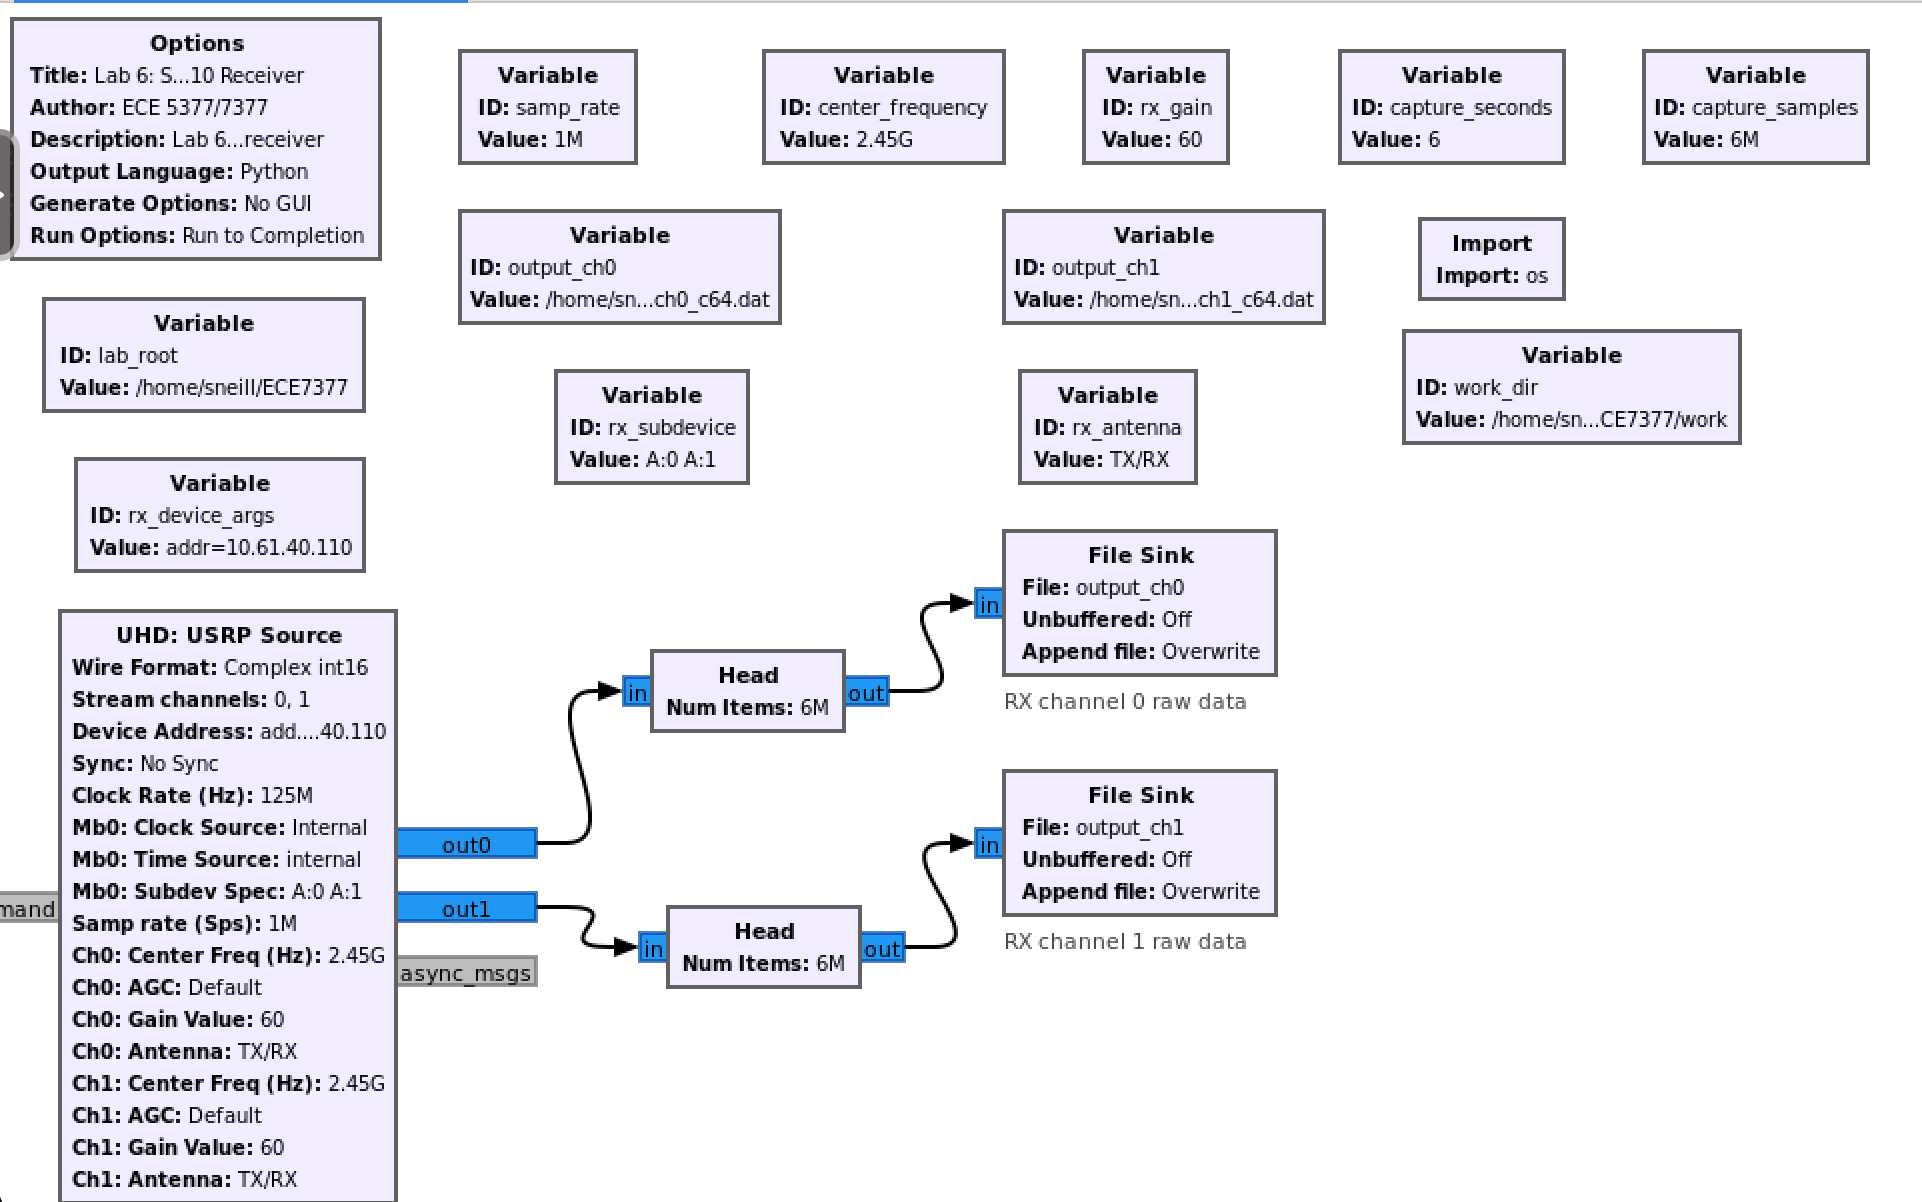

### Monitor Flowgraph

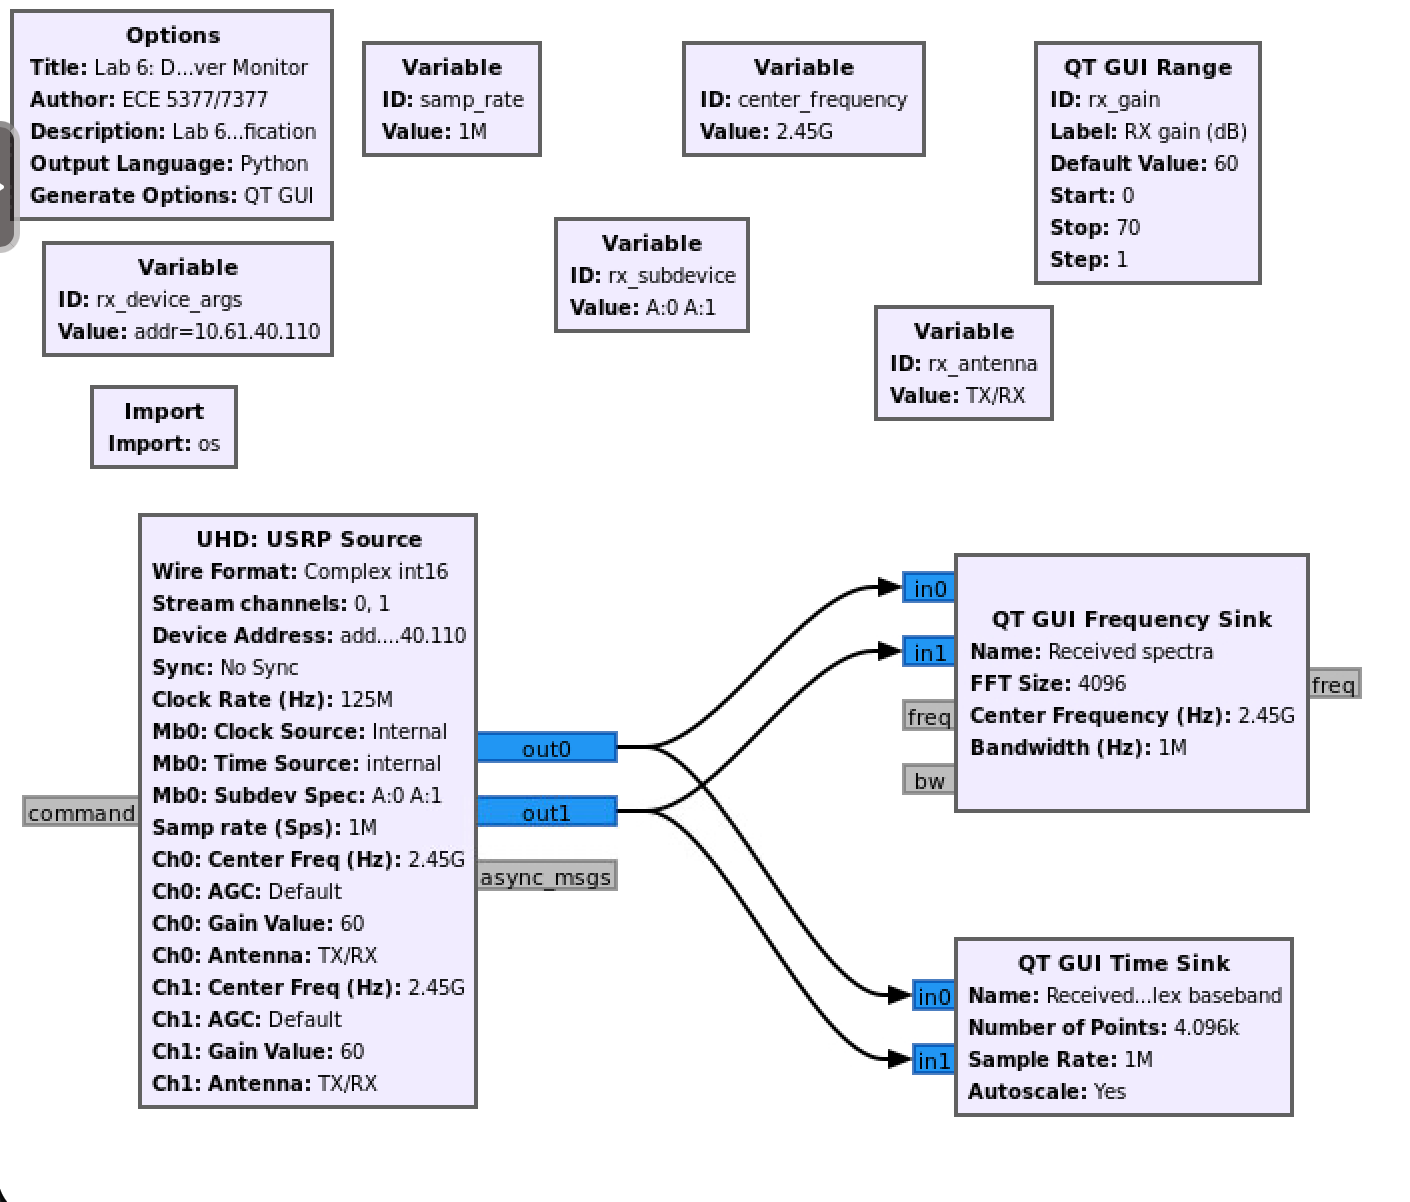

### Transmitter Flowgraph

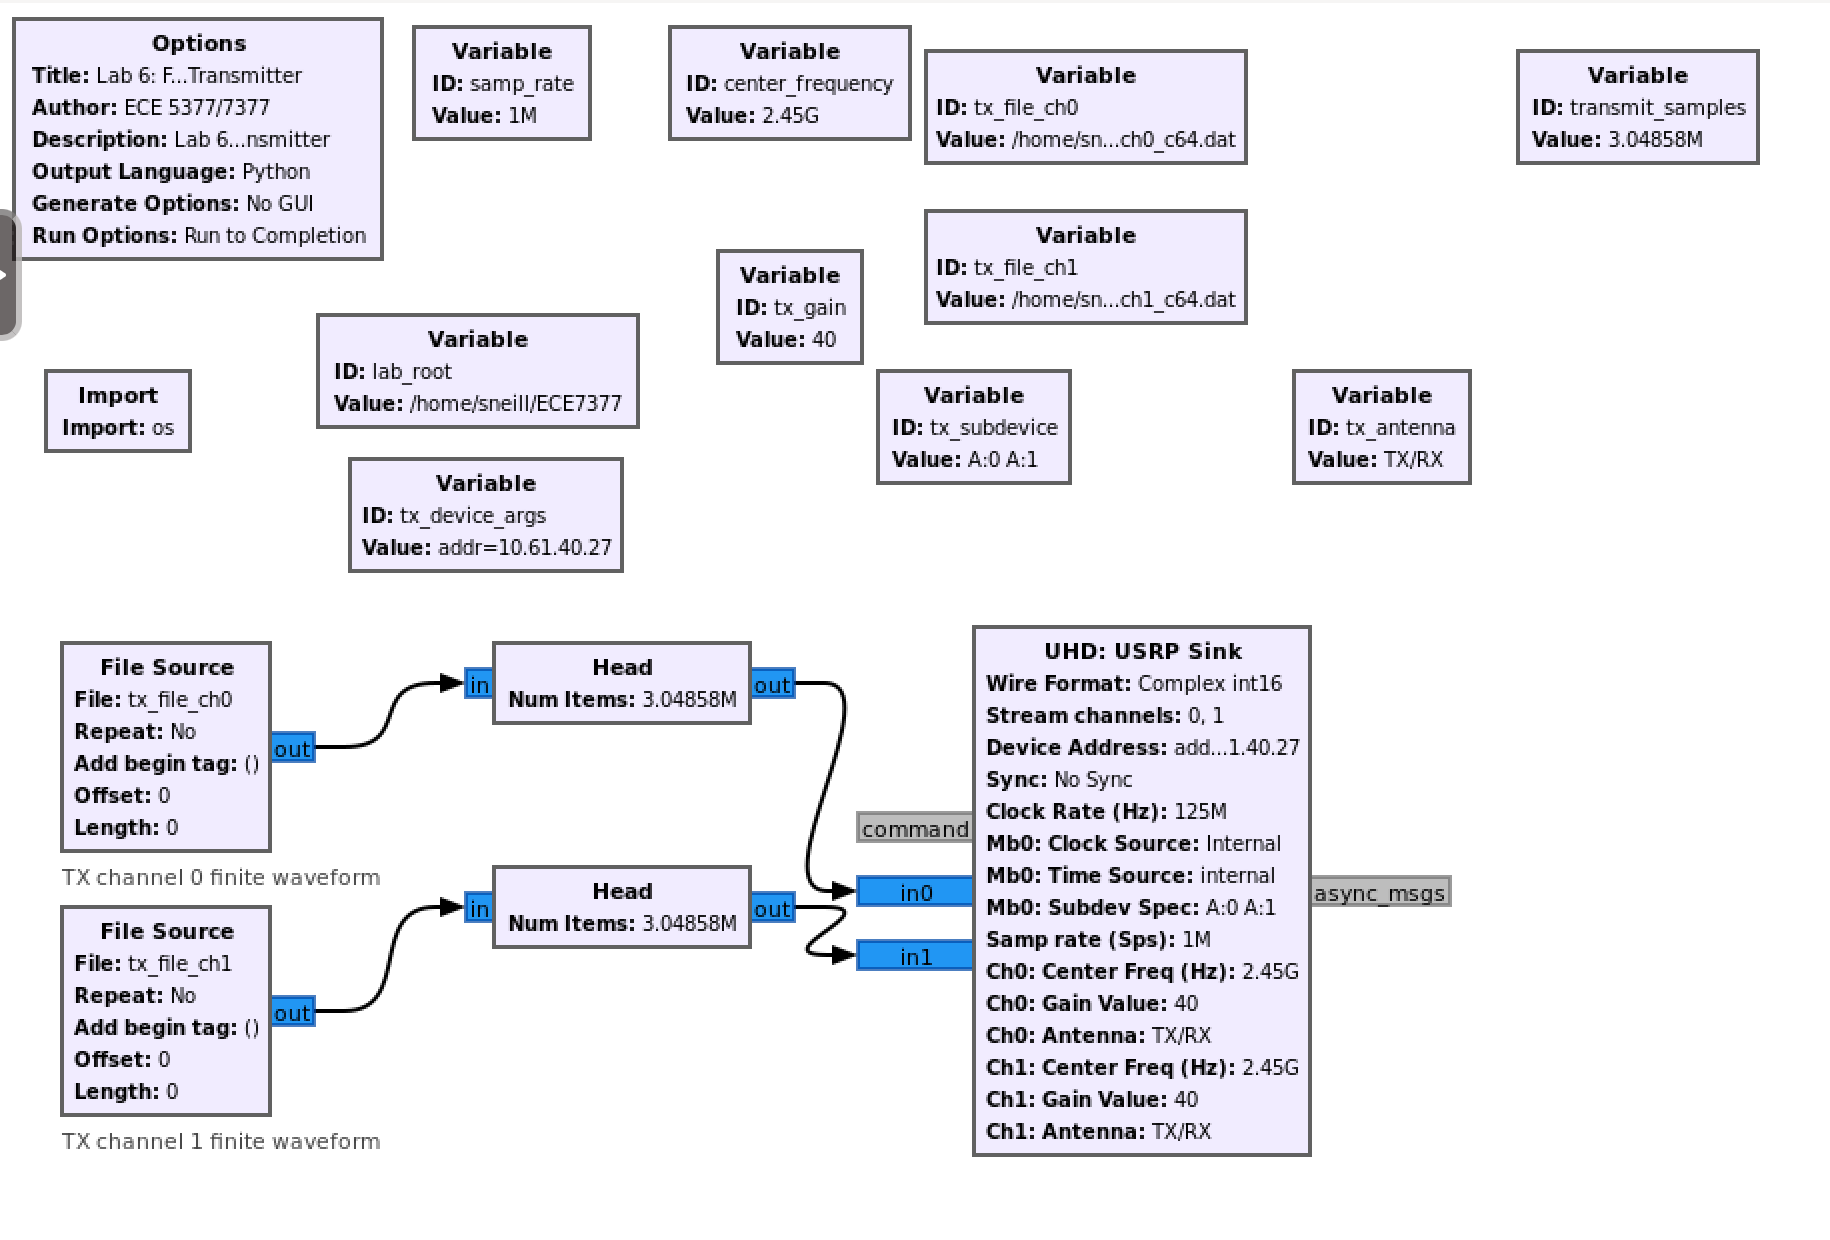

## GNU Radio capture

Use the provided transmitter, receiver monitor, and finite receiver flowgraphs as directed in the manual. Run the receiver before the transmitter. Save one noise-only record and one dual-channel record at each TX gain.

In [9]:
from pathlib import Path
import sys

LAB_ROOT = Path("/home/sneill/ECE7377")
sys.path.insert(0, str(LAB_ROOT / "support"))

import lab6_tools as tools

output_dir = LAB_ROOT / "expected_figures"

results = tools.generate_simulation(output_dir)

print("Figures generated successfully!")
for file in sorted(output_dir.glob("*.png")):
    print(file.name)

Figures generated successfully!
task1_diversity_by_method.png
task1_diversity_comparison.png
task1_mimo_capacity_and_estimation.png
task2_waveform_schedule.png


<span style='color:#1464b4'><b>Report:</b> Include the verification spectrum.</span>

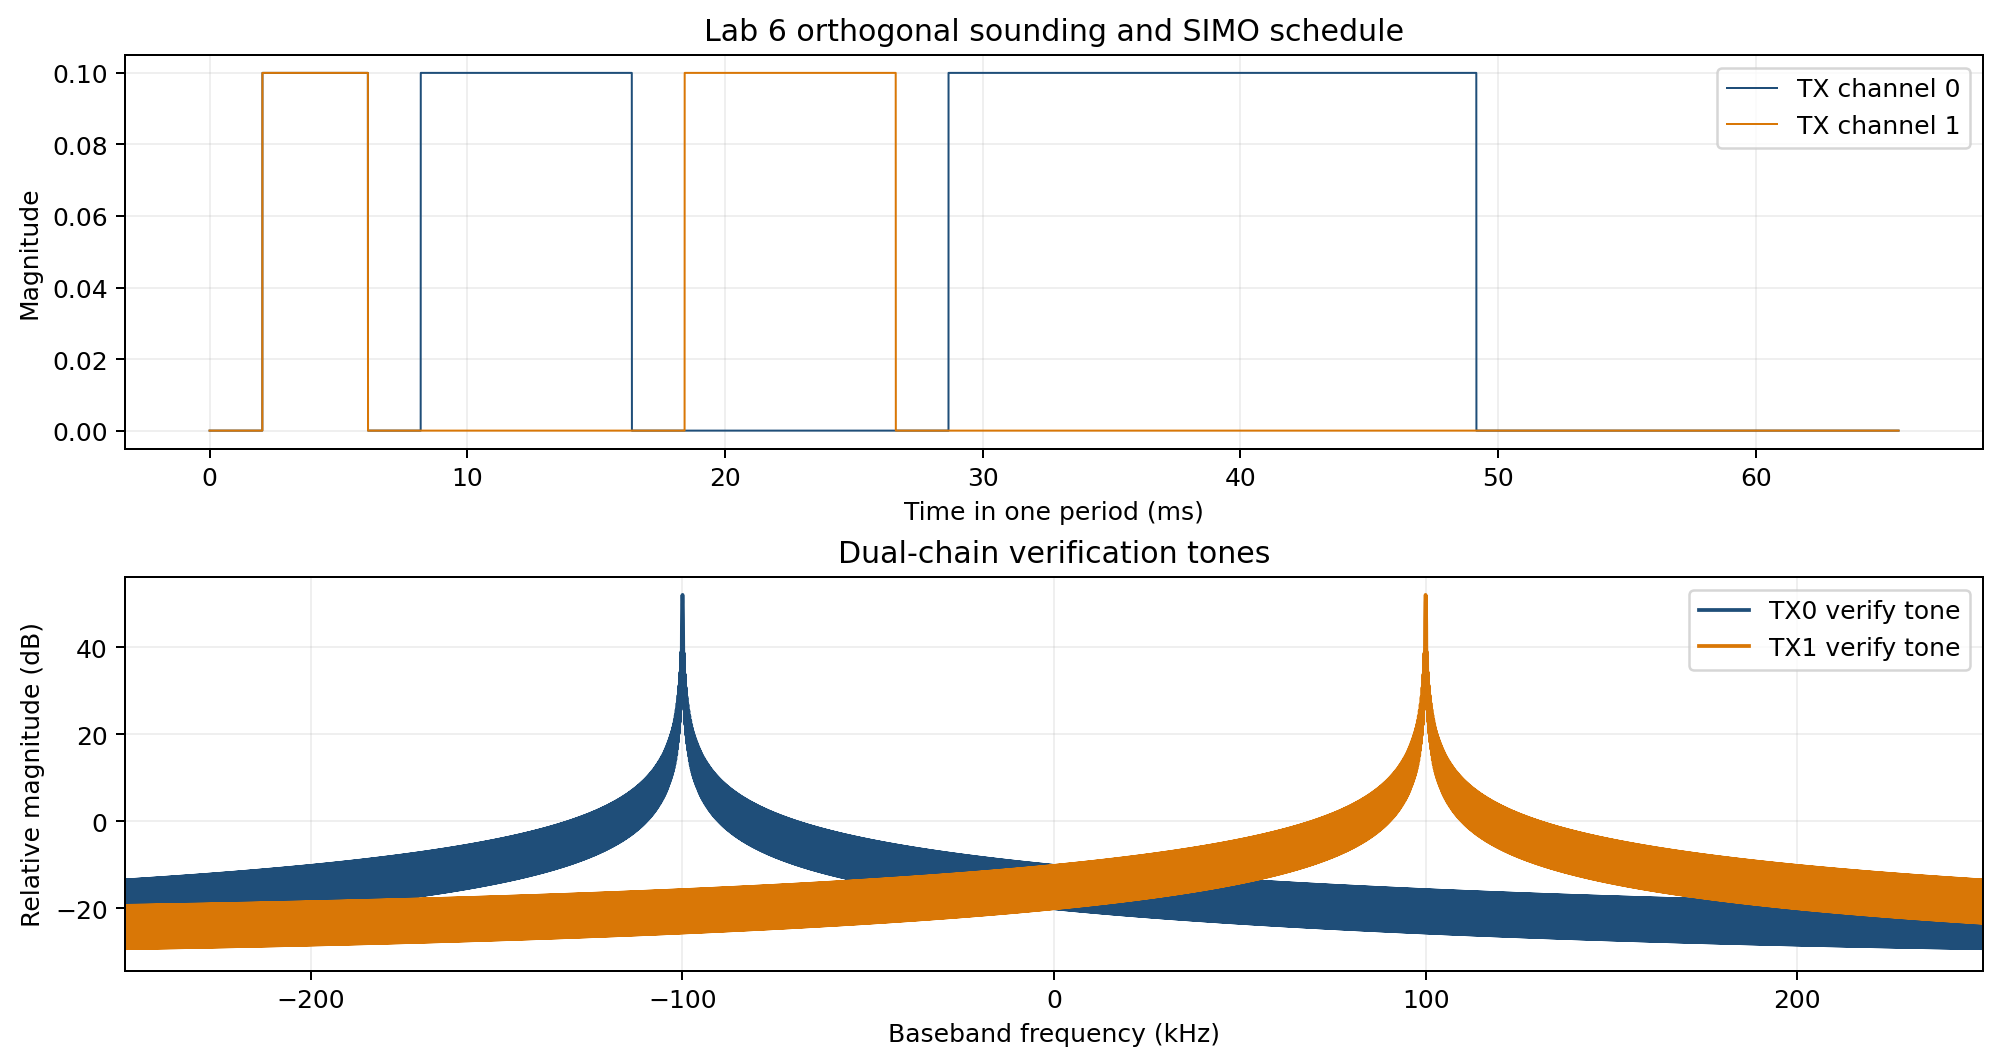

In [4]:
display(Image(filename=str(LAB_ROOT/'expected_figures/task2_waveform_schedule.png'), width=900))

## Analyze the captures

The library performs acquisition, CFO correction, plotting, and repeated-frame aggregation. You are responsible for checking the matrix calculation and interpreting the result.

In [5]:
capture_dir = LAB_ROOT/'work/captures'
figure_dir = LAB_ROOT/'work/figures'
hardware = tools.analyze_hardware(capture_dir, figure_dir)
for gain, values in hardware['gains'].items():
    print(gain, 'frames', values['analyzed_frames'], 'capacity', round(values['mimo_capacity_mean_bps_hz'],3), 'condition', round(values['condition_number_mean'],3))

tx40 frames 15 capacity 35.06 condition 9.118
tx45 frames 15 capacity 40.666 condition 9.105
tx50 frames 15 capacity 43.978 condition 9.105


<span style='color:#1464b4'><b>Report:</b> Include one channel matrix per gain, MIMO and SISO capacity versus gain, and condition number.</span>

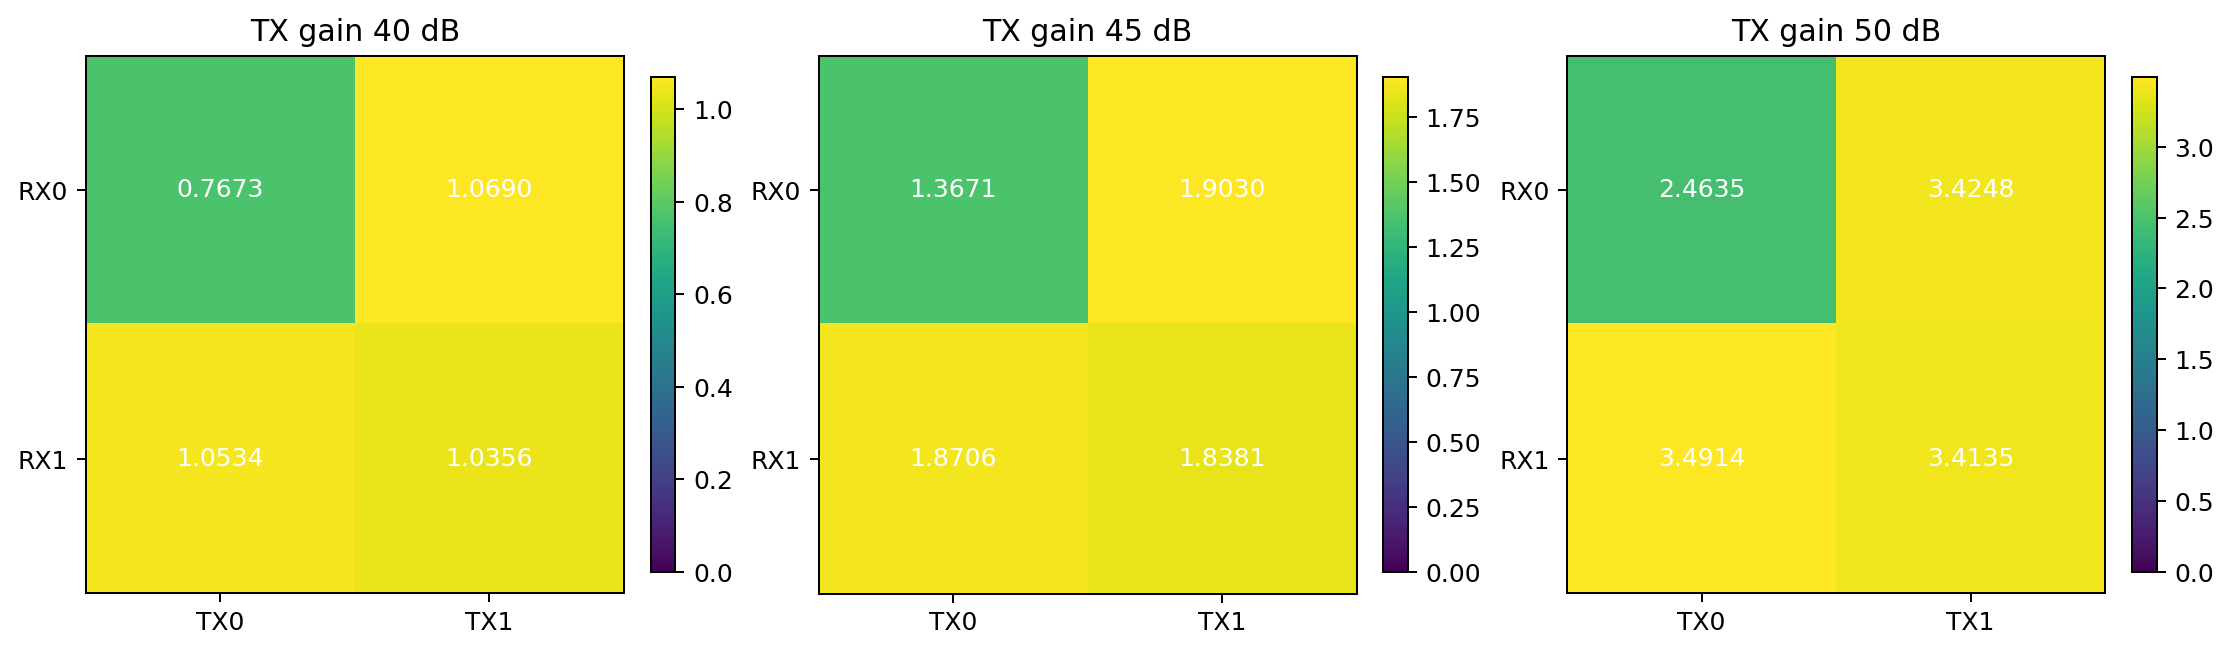

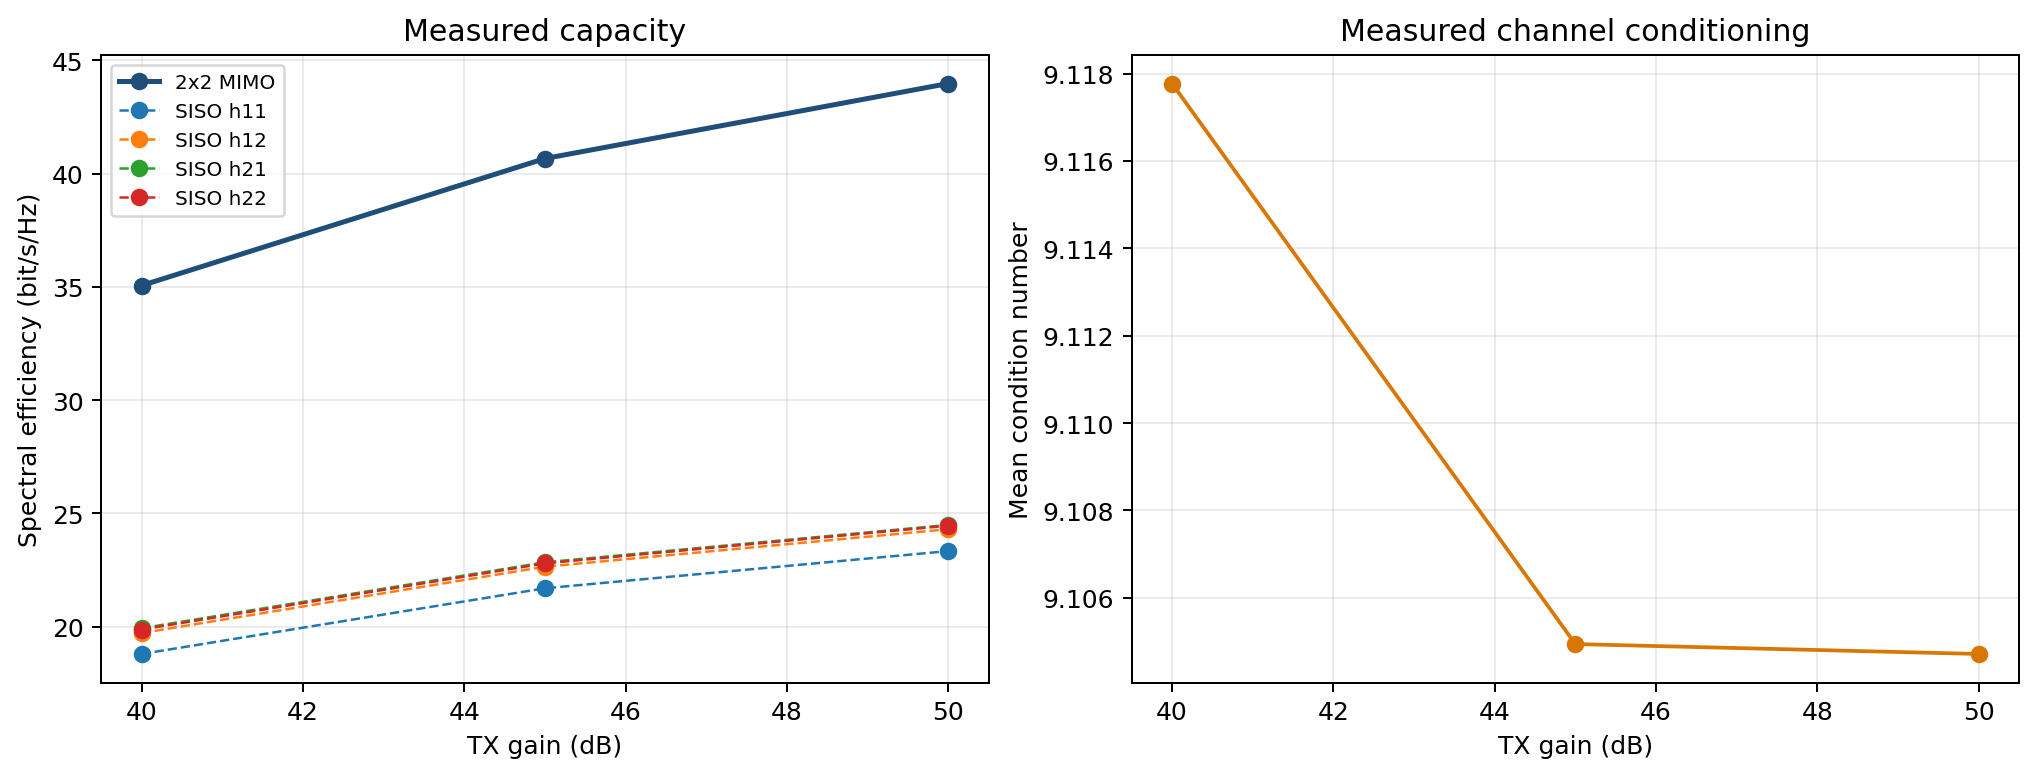

In [6]:
display(Image(filename=str(figure_dir/'task2_hardware_channel_matrices.png'), width=1000))
display(Image(filename=str(figure_dir/'task2_hardware_capacity.png'), width=900))

## Check one capacity calculation

In [8]:
middle = hardware['gains'][f'tx{tx_gains_db[1]}']
h_real = np.array(middle['mimo_channel_reference']['real'])
h_imag = np.array(middle['mimo_channel_reference']['imag'])
h_hat = h_real + 1j*h_imag
noise = np.mean(hardware['noise_variance'])

rho = 2 * (0.1 ** 2) / noise
capacity_check = np.log2(
    np.linalg.det(
        np.eye(h_hat.shape[0]) +
        (rho / h_hat.shape[1]) * (h_hat @ h_hat.conj().T)
    )
).real
print('Representative H:\n',np.round(h_hat,4))
print('Capacity check:',capacity_check)
print('Stored reference-frame capacity:',middle['mimo_capacity_reference_bps_hz'])

Representative H:
 [[1.3026-0.4149j 1.8078-0.5943j]
 [1.8543-0.2464j 1.8197+0.2599j]]
Capacity check: 40.67147705360864
Stored reference-frame capacity: 40.67147705360865


<span style='color:#1464b4'><b>Report:</b> Explain why orthogonal pilots are required.</span>

Orthogonal pilots are used so that each column of the channel matrix H can be estimated separately. In this experiment, the waveform transmits a TX0-only pilot followed by a TX1-only pilot at the same baseband frequency. Because the pilots are time-orthogonal, the receiver can isolate the channel contribution from each transmit antenna and estimate all four channel coefficients of the 2×2 MIMO channel matrix. If both transmitters sent the same-frequency pilot simultaneously, their contributions would overlap, making the channel estimates more difficult and less accurate.